# RoadGuard AI — Notebook 01: Video Detection & Tracking

This notebook loads a local dashcam video, runs YOLO object detection, tracks objects with ByteTrack, and saves an annotated video plus frame-level JSON events.

**Important:** object detection/tracking is not accident classification. This notebook establishes the video-processing baseline; temporal incident detection comes in a later notebook.

## 1. Check the environment and GPU

In [9]:
import sys, platform
from pathlib import Path
import cv2
import torch
import numpy as np
import pandas as pd
from ultralytics import YOLO
from tqdm.auto import tqdm
import json

print('Python:', sys.version)
print('Platform:', platform.platform())
print('OpenCV:', cv2.__version__)
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU not detected. Install a CUDA-enabled PyTorch build before expecting GPU inference.')

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Platform: Windows-11-10.0.26300-SP0
OpenCV: 5.1.0
PyTorch: 2.6.0+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Set project paths

In [10]:
# If your project is in another location, change PROJECT_DIR.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_DIR / 'data' / 'raw' / 'dota' / 'videos'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
ANNOTATED_DIR = OUTPUT_DIR / 'annotated_videos'
EVENT_DIR = OUTPUT_DIR / 'events'

ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)
EVENT_DIR.mkdir(parents=True, exist_ok=True)

print('Project:', PROJECT_DIR.resolve())
print('Video folder:', DATA_DIR.resolve())
print('Output folder:', OUTPUT_DIR.resolve())

Project: C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series
Video folder: C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series\data\raw\dota\videos
Output folder: C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series\outputs


## 3. Find a video file

Official DoTA **frame/video Google Drive links are dead** (404), and the original YouTube URLs are gone. Annotations still live under `data/raw/dota/`.

Until you fetch the Baidu frame mirror (`scripts/download_dota_media.py` documents it), this notebook uses real dashcam **CCD Crash** clips copied into `data/raw/dota/videos/` (`ccd_crash_*.mp4`). Prefer those over `sample_dashcam.mp4`.

In [11]:
video_extensions = {'.mp4', '.avi', '.mov', '.mkv'}
video_files = sorted(
    p for p in DATA_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in video_extensions
) if DATA_DIR.exists() else []
print(f'Found {len(video_files)} video(s).')
for p in video_files[:10]:
    print(p)

if not video_files:
    raise FileNotFoundError(
        f'No videos in {DATA_DIR}. Run: python scripts/download_dota_media.py --ccd'
    )

# Prefer real crash clips over the tiny synthetic sample.
def _video_rank(path: Path) -> tuple:
    name = path.name.lower()
    if name.startswith('ccd_crash_') or 'crash' in name:
        return (0, name)
    if name.startswith('sample_'):
        return (2, name)
    return (1, name)

VIDEO_PATH = sorted(video_files, key=_video_rank)[0]
print('Selected video:', VIDEO_PATH)

Found 1 video(s).
C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series\data\raw\dota\videos\sample_dashcam.mp4
Selected video: C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series\data\raw\dota\videos\sample_dashcam.mp4


## 4. Inspect video metadata and preview a frame

{'fps': 15.0, 'frames': 45, 'width': 640, 'height': 360, 'duration_seconds': 3.0}


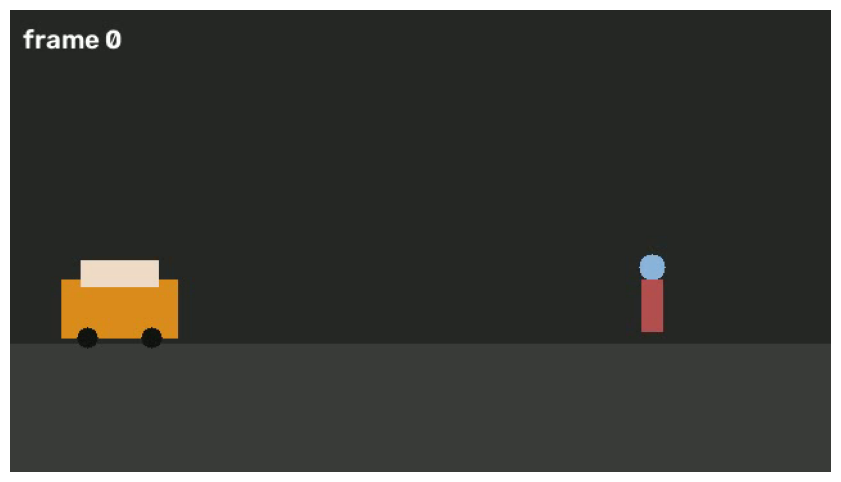

In [12]:
cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError(f'OpenCV could not open {VIDEO_PATH}')

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration_sec = frame_count / fps if fps and fps > 0 else None
ok, first_frame = cap.read()
cap.release()

print({'fps': fps, 'frames': frame_count, 'width': width, 'height': height, 'duration_seconds': duration_sec})
if ok:
    from matplotlib import pyplot as plt
    plt.figure(figsize=(12, 6))
    plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
    plt.axis('off');
else:
    raise RuntimeError('Could not read the first frame.')

## 5. Load YOLO

The first run downloads the pretrained `yolov8n.pt` weights automatically. This is a general-purpose pretrained detector, not a DoTA-trained accident classifier.

In [13]:
model = YOLO('yolov8n.pt')
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Inference device:', DEVICE)

Inference device: 0


## 6. Run object detection and ByteTrack

This processes the video and writes an annotated copy. The tracker assigns IDs to objects across frames when possible.

In [14]:
results_stream = model.track(
    source=str(VIDEO_PATH),
    stream=True,
    persist=True,
    tracker='bytetrack.yaml',
    device=DEVICE,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    save=True,
    project=str(ANNOTATED_DIR),
    name='yolo_bytetrack',
    exist_ok=True,
    verbose=False
)

event_rows = []
for frame_idx, result in enumerate(tqdm(results_stream, desc='Processing video')):
    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        continue

    xyxy = boxes.xyxy.cpu().numpy()
    confs = boxes.conf.cpu().numpy()
    class_ids = boxes.cls.cpu().numpy().astype(int)
    track_ids = boxes.id.cpu().numpy().astype(int) if boxes.id is not None else [None] * len(boxes)

    frame_time = frame_idx / fps if fps and fps > 0 else None
    for box, confidence, class_id, track_id in zip(xyxy, confs, class_ids, track_ids):
        x1, y1, x2, y2 = [float(v) for v in box]
        event_rows.append({
            'frame_index': frame_idx,
            'timestamp_seconds': round(frame_time, 3) if frame_time is not None else None,
            'class_id': int(class_id),
            'class_name': model.names[int(class_id)],
            'confidence': round(float(confidence), 4),
            'track_id': int(track_id) if track_id is not None else None,
            'x1': round(x1, 2), 'y1': round(y1, 2),
            'x2': round(x2, 2), 'y2': round(y2, 2)
        })

events_df = pd.DataFrame(event_rows)
print('Detection rows:', len(events_df))
events_df.head()

Processing video: 0it [00:00, ?it/s]

Results saved to C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series\outputs\annotated_videos\yolo_bytetrack
Detection rows: 0


""


## 7. Save event metadata as CSV and JSON

In [15]:
video_stem = VIDEO_PATH.stem
csv_path = EVENT_DIR / f'{video_stem}_detections.csv'
json_path = EVENT_DIR / f'{video_stem}_detections.json'

events_df.to_csv(csv_path, index=False)
events_df.to_json(json_path, orient='records', indent=2)
print('Saved CSV:', csv_path.resolve())
print('Saved JSON:', json_path.resolve())

Saved CSV: C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series\outputs\events\sample_dashcam_detections.csv
Saved JSON: C:\Users\akhil\OneDrive\Documents\AI_Agent_book_series\outputs\events\sample_dashcam_detections.json


## 8. Explore detected objects

In [16]:
if not events_df.empty:
    display(events_df['class_name'].value_counts().rename_axis('object_class').reset_index(name='detections'))
    display(events_df.groupby('class_name')['confidence'].mean().sort_values(ascending=False).to_frame('mean_confidence'))
else:
    print('No objects were detected. Try another clip or lower the confidence threshold.')

No objects were detected. Try another clip or lower the confidence threshold.


## 9. Next milestone

Next we will parse the DoTA annotation format, align ground-truth anomaly labels with video timestamps, and build an event-level evaluation pipeline. We will then add temporal features such as object trajectories, sudden deceleration, relative distance, and scene changes. Do not label a detection as an accident based only on a vehicle/person bounding box.